# Machine Learning Baseline

This notebook builds a leakage-aware classical machine learning baseline
for Microsoft GUIDE security incident triage.

Target:
- BenignPositive
- FalsePositive
- TruePositive

The model uses grouped train/validation splitting to ensure that evidence
belonging to the same incident does not appear in both sets.

## Imports

In [57]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

## Paths

In [58]:
current_path = Path.cwd()

if current_path.name == "notebooks":
    PROJECT_ROOT = current_path.parent
else:
    PROJECT_ROOT = current_path

DATA_DIR = PROJECT_ROOT / "data" / "raw"

TRAIN_PATH = DATA_DIR / "GUIDE_Train.csv"

print(PROJECT_ROOT)
print(TRAIN_PATH)

c:\Users\zaaaa\OneDrive\Υπολογιστής\New folder\Python Projects\ai-security-incident-triage
c:\Users\zaaaa\OneDrive\Υπολογιστής\New folder\Python Projects\ai-security-incident-triage\data\raw\GUIDE_Train.csv


In [59]:
df = pd.read_csv(
    TRAIN_PATH,
    nrows=100_000,
    low_memory=False
)

print(df.shape)

(100000, 45)


## Clean Target

In [60]:
TARGET = "IncidentGrade"

print(df[TARGET].value_counts(dropna=False))

IncidentGrade
BenignPositive    43024
TruePositive      34887
FalsePositive     21564
NaN                 525
Name: count, dtype: int64


In [61]:
df = df.dropna(
    subset=[TARGET]
).copy()

print("Rows after removing missing target:", len(df))

Rows after removing missing target: 99475


## Create grouping key

In [62]:
df["IncidentGroup"] = (
    df["OrgId"].astype(str)
    + "_"
    + df["IncidentId"].astype(str)
)

## Timestamp feature engineering

In [63]:
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce",
    utc=True
)

df["Hour"] = df["Timestamp"].dt.hour

df["DayOfWeek"] = (
    df["Timestamp"]
    .dt.dayofweek
)

df["IsWeekend"] = (
    df["DayOfWeek"] >= 5
).astype(int)

In [64]:
df[[
    "Timestamp",
    "Hour",
    "DayOfWeek",
    "IsWeekend"
]].head()

,Timestamp,Hour,DayOfWeek,IsWeekend
0,2024-06-04 06:05:15+00:00,6,1,0
1,2024-06-14 03:01:25+00:00,3,4,0
2,2024-06-13 04:52:55+00:00,4,3,0
3,2024-06-10 16:39:36+00:00,16,0,0
4,2024-06-15 01:08:07+00:00,1,5,1


## MITRE simple feature

In [65]:
df["HasMitreTechnique"] = (
    df["MitreTechniques"]
    .notna()
    .astype(int)
)

## Define feature set

In [66]:
categorical_features = [
    "DetectorId",
    "AlertTitle",
    "Category",
    "EntityType",
    "EvidenceRole",

    "RegistryKey",
    "RegistryValueName",
    "RegistryValueData",

    "ApplicationId",
    "ApplicationName",
    "OAuthApplicationId",

    "ResourceIdName",

    "OSFamily",
    "OSVersion",

    "CountryCode",
    "State",
    "City"
]

In [67]:
numeric_features = [
    "Hour",
    "DayOfWeek",
    "IsWeekend",
    "HasMitreTechnique"
]

## X = features and y = target

In [68]:
FEATURES = (
    categorical_features
    + numeric_features
)

X = df[FEATURES].copy()
y = df[TARGET].copy()

groups = df["IncidentGroup"].copy()

## Grouped split

In [69]:
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        X,
        y,
        groups=groups
    )
)

In [70]:
X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

groups_train = groups.iloc[train_idx]
groups_val = groups.iloc[val_idx]

## Check for Leakage

In [71]:
train_groups = set(groups_train)
val_groups = set(groups_val)

overlap = train_groups.intersection(
    val_groups
)

print("Train rows:", len(X_train))
print("Validation rows:", len(X_val))

print(
    "Overlapping incidents:",
    len(overlap)
)

Train rows: 79580
Validation rows: 19895
Overlapping incidents: 0


## Check target distributions

In [72]:
print("TRAIN")
print(
    y_train.value_counts(
        normalize=True
    ).round(3)
)

print("\nVALIDATION")
print(
    y_val.value_counts(
        normalize=True
    ).round(3)
)

TRAIN
IncidentGrade
BenignPositive    0.433
TruePositive      0.351
FalsePositive     0.217
Name: proportion, dtype: float64

VALIDATION
IncidentGrade
BenignPositive    0.433
TruePositive      0.351
FalsePositive     0.217
Name: proportion, dtype: float64


## Preprocessor

In [73]:
numeric_transformer = StandardScaler()

In [74]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numeric",
            numeric_transformer,
            numeric_features
        )
    ]
)

## Logistic Regression

In [75]:
model = LogisticRegression(
    solver="saga",
    max_iter=3000,
    class_weight="balanced",
    random_state=42
)

## Pipeline

In [76]:
baseline_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor
        ),
        (
            "classifier",
            model
        )
    ]
)

## Training

In [77]:
_ = baseline_pipeline.fit(
    X_train,
    y_train
)

print("Baseline training completed.")

Baseline training completed.


In [78]:
classifier = baseline_pipeline.named_steps[
    "classifier"
]

print(
    "Iterations:",
    classifier.n_iter_
)

Iterations: [75]


## Predictions

In [79]:
y_pred = baseline_pipeline.predict(
    X_val
)

## Metrics

In [80]:
accuracy = accuracy_score(
    y_val,
    y_pred
)

precision_macro = precision_score(
    y_val,
    y_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_val,
    y_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_val,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Accuracy:        {accuracy:.4f}")
print(f"Macro Precision: {precision_macro:.4f}")
print(f"Macro Recall:    {recall_macro:.4f}")
print(f"Macro F1:        {f1_macro:.4f}")

Accuracy:        0.7576
Macro Precision: 0.7469
Macro Recall:    0.7343
Macro F1:        0.7387


## Classification report

In [81]:
print(
    classification_report(
        y_val,
        y_pred,
        digits=4,
        zero_division=0
    )
)

                precision    recall  f1-score   support

BenignPositive     0.7638    0.8536    0.8062      8605
 FalsePositive     0.6757    0.6332    0.6537      4313
  TruePositive     0.8012    0.7161    0.7562      6977

      accuracy                         0.7576     19895
     macro avg     0.7469    0.7343    0.7387     19895
  weighted avg     0.7578    0.7576    0.7556     19895



## Confusion Matrix

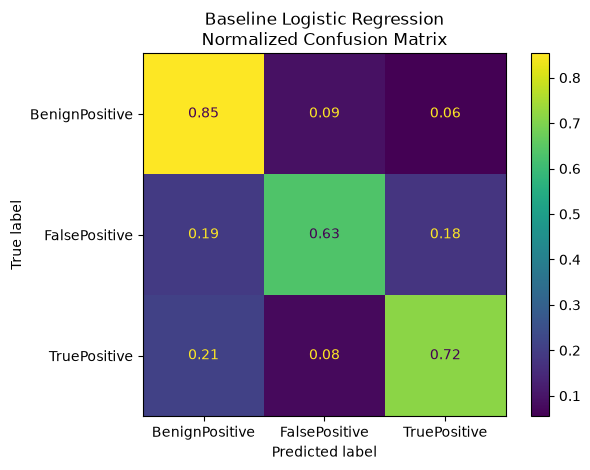

In [82]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    normalize="true",
    values_format=".2f"
)

plt.title(
    "Baseline Logistic Regression\nNormalized Confusion Matrix"
)

plt.tight_layout()
plt.show()